# Predicción del consumo eléctrico de viviendas
**Módulo:** Sistemas de Aprendizaje Automático · **Tipo:** Regresión supervisada · **Objetivo:** `consumo_mensual_kwh`

## Parte 1 — Carga e inspección del dataset
Antes de entrenar nada hay que saber **qué datos tenemos**: tamaño, tipos, valores ausentes, duplicados y rangos. De aquí salen las decisiones del cribado (Parte 2).

In [1]:
from datetime import datetime
from zoneinfo import ZoneInfo
import platform, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
IN_COLAB = "google.colab" in sys.modules
# Colab servers run in UTC: show the local Spanish time explicitly for the screenshots
print("Fecha y hora (Europe/Madrid):", datetime.now(ZoneInfo("Europe/Madrid")).strftime("%d/%m/%Y %H:%M:%S"))
print("Entorno:", "Google Colab" if IN_COLAB else "Local", "| Python", platform.python_version(),
      "| pandas", pd.__version__)

Fecha y hora (Europe/Madrid): 24/11/2026 15:35:34
Entorno: Local | Python 3.15.2 | pandas 3.1.1


### 1.1 Carga del CSV
En Google Colab, si el archivo no está en la sesión, se abre un selector para subirlo.

In [2]:
import os

CSV = "dataset_consumo_electrico_30000.csv"
if IN_COLAB and not os.path.exists(CSV):
    from google.colab import files
    files.upload()  # select dataset_consumo_electrico_30000.csv from your computer

df = pd.read_csv(CSV)
print("Filas, columnas:", df.shape)
df.head()

Filas, columnas: (30000, 24)


,id_registro,edad_vivienda_anios,superficie_m2,numero_personas,habitaciones,dias_facturacion,temperatura_media_c,temperatura_minima_c,temperatura_maxima_c,mes,zona_climatica,tipo_vivienda,nivel_aislamiento,tipo_calefaccion,tipo_agua_caliente,aire_acondicionado,paneles_solares,numero_electrodomesticos,teletrabajo,nivel_ocupacion_diurna,potencia_contratada_kw,tipo_tarifa,anio,consumo_mensual_kwh
0,1,86,175.2,2.0,5.0,31.0,10.3,5.3,21.9,3,Mediterránea,Piso,Alto,Bomba de calor,Gas,No,No,7.0,No,Media,3.41,Fija,2026,601.7
1,2,18,146.6,3.0,5.0,31.0,8.2,-1.9,12.0,7,Continental,Piso,Medio,Bomba de calor,Gas,No,No,10.0,No,Alta,5.23,Fija,2021,731.6
2,3,2,103.8,4.0,2.0,30.0,19.8,7.2,25.0,12,Atlántica,Piso,Alto,Biomasa,Solar,Sí,No,8.0,Sí,Alta,4.54,Fija,2023,499.2
3,4,64,85.0,5.0,3.0,31.0,19.9,12.3,29.3,1,Continental,Casa,Alto,Gas,Gas,Sí,No,9.0,No,Alta,4.87,Fija,2023,721.2
4,5,36,74.8,2.0,1.0,30.0,9.7,1.8,13.8,5,Mediterránea,Piso,Bajo,Gas,Solar,No,No,4.0,No,Media,2.74,Fija,2023,314.8


### 1.2 Tipos de datos
Separamos numéricas y categóricas: los modelos de scikit-learn solo entienden números, así que las categóricas habrá que codificarlas más adelante.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_registro               30000 non-null  int64  
 1   edad_vivienda_anios       30000 non-null  int64  
 2   superficie_m2             29997 non-null  float64
 3   numero_personas           29988 non-null  float64
 4   habitaciones              29987 non-null  float64
 5   dias_facturacion          29980 non-null  float64
 6   temperatura_media_c       29991 non-null  float64
 7   temperatura_minima_c      29989 non-null  float64
 8   temperatura_maxima_c      29999 non-null  float64
 9   mes                       30000 non-null  int64  
 10  zona_climatica            30000 non-null  str    
 11  tipo_vivienda             30000 non-null  str    
 12  nivel_aislamiento         30000 non-null  str    
 13  tipo_calefaccion          30000 non-null  str    
 14  tipo_agua_calient

In [4]:
TARGET = "consumo_mensual_kwh"
num_cols = df.select_dtypes(include="number").columns.drop(["id_registro", TARGET]).tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numéricas  :", num_cols)
print("Categóricas:", cat_cols)

Numéricas  : ['edad_vivienda_anios', 'superficie_m2', 'numero_personas', 'habitaciones', 'dias_facturacion', 'temperatura_media_c', 'temperatura_minima_c', 'temperatura_maxima_c', 'mes', 'numero_electrodomesticos', 'potencia_contratada_kw', 'anio']
Categóricas: ['zona_climatica', 'tipo_vivienda', 'nivel_aislamiento', 'tipo_calefaccion', 'tipo_agua_caliente', 'aire_acondicionado', 'paneles_solares', 'teletrabajo', 'nivel_ocupacion_diurna', 'tipo_tarifa']


### 1.3 Valores ausentes y duplicados

In [5]:
nulos = df.isna().sum()
nulos[nulos > 0].to_frame("nulos").assign(porcentaje=lambda t: (t["nulos"] / len(df) * 100).round(3))

,nulos,porcentaje
superficie_m2,3,0.010
numero_personas,12,0.040
habitaciones,13,0.043
dias_facturacion,20,0.067
temperatura_media_c,9,0.030
temperatura_minima_c,11,0.037
temperatura_maxima_c,1,0.003
paneles_solares,2,0.007
numero_electrodomesticos,4,0.013
nivel_ocupacion_diurna,1,0.003


In [6]:
print("Filas con algún nulo:", df.isna().any(axis=1).sum())
print("Duplicados exactos:", df.duplicated().sum())
print("Duplicados ignorando id_registro:", df.drop(columns="id_registro").duplicated().sum())

Filas con algún nulo: 61
Duplicados exactos: 0
Duplicados ignorando id_registro: 0


### 1.4 Estadísticos de las variables numéricas
Buscamos valores imposibles (negativos, superficies absurdas, temperaturas incoherentes).

In [7]:
df[num_cols + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad_vivienda_anios,30000.0,50.16,29.18,0.0,25.00,50.00,75.00,100.00
superficie_m2,29997.0,115.37,40.99,30.0,87.30,114.70,143.10,283.60
numero_personas,29988.0,3.57,1.59,1.0,2.00,3.00,5.00,8.00
habitaciones,29987.0,3.87,1.57,1.0,3.00,4.00,5.00,9.00
dias_facturacion,29980.0,30.43,0.67,28.0,30.00,30.00,31.00,31.00
temperatura_media_c,29991.0,16.01,7.91,-5.0,10.60,16.00,21.30,38.00
temperatura_minima_c,29989.0,7.52,8.30,-15.0,1.90,7.40,13.10,30.00
temperatura_maxima_c,29999.0,23.51,8.34,-1.8,17.80,23.50,29.20,48.00
mes,30000.0,6.49,3.44,1.0,3.00,7.00,9.00,12.00
numero_electrodomesticos,29996.0,7.51,2.19,2.0,6.00,8.00,9.00,16.00


### 1.5 Categorías de las variables categóricas
Comprobamos que no hay erratas (p. ej. `Si` vs `Sí`) ni categorías raras.

In [8]:
for c in cat_cols:
    print(f"{c}: {df[c].value_counts(dropna=False).to_dict()}")

zona_climatica: {'Continental': 10476, 'Mediterránea': 9031, 'Atlántica': 7462, 'De montaña': 3031}
tipo_vivienda: {'Piso': 17469, 'Casa': 8170, 'Adosado': 4361}
nivel_aislamiento: {'Medio': 14956, 'Bajo': 7551, 'Alto': 7493}
tipo_calefaccion: {'Gas': 10287, 'Eléctrica': 7543, 'Bomba de calor': 6447, 'Ninguna': 3363, 'Biomasa': 2360}
tipo_agua_caliente: {'Gas': 13508, 'Eléctrica': 12856, 'Solar': 3636}
aire_acondicionado: {'No': 15558, 'Sí': 14442}
paneles_solares: {'No': 25241, 'Sí': 4757, nan: 2}
teletrabajo: {'No': 20322, 'Sí': 9678}
nivel_ocupacion_diurna: {'Media': 14101, 'Alta': 8466, 'Baja': 7432, nan: 1}
tipo_tarifa: {'Fija': 14296, 'Discriminación horaria': 10197, 'Indexada': 5507}


### 1.6 Coherencia interna de las temperaturas
Por lógica debe cumplirse `mínima ≤ media ≤ máxima`. Además, si `mes` tuviera sentido climático, la temperatura media debería cambiar con el mes.

In [9]:
incoherentes = df[(df["temperatura_minima_c"] > df["temperatura_media_c"]) |
                  (df["temperatura_media_c"] > df["temperatura_maxima_c"])]
print("Filas con temperaturas incoherentes:", len(incoherentes))
df.groupby("mes")["temperatura_media_c"].mean().round(2).to_frame("temp_media_por_mes").T

Filas con temperaturas incoherentes: 0


mes,1,2,3,4,5,6,7,8,9,10,11,12
temp_media_por_mes,15.86,15.67,15.95,16.02,16.27,16.04,16.13,15.75,15.94,16.34,16.09,16.08


### 1.7 Distribución de la variable objetivo

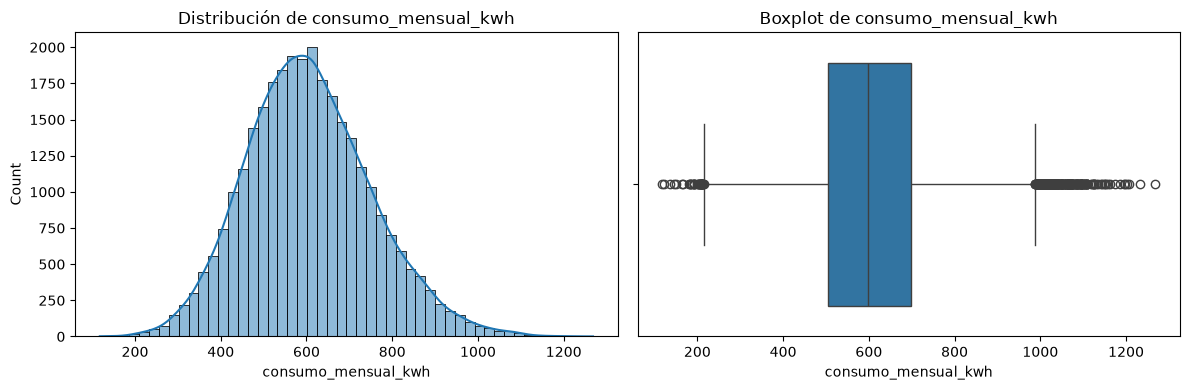

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribución de consumo_mensual_kwh")
sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("Boxplot de consumo_mensual_kwh")
plt.tight_layout()
plt.show()

## Parte 2 — Cribado de datos
### 2.1 ¿Los nulos aparecen al azar?
Antes de eliminar filas comprobamos que las filas con nulos no son un grupo especial. Si su consumo fuera muy distinto al del resto, borrarlas **sí** sesgaría el modelo.

In [11]:
con_nulos = df.isna().any(axis=1)
pd.DataFrame({
    "filas con nulos": df.loc[con_nulos, TARGET].describe(),
    "filas completas": df.loc[~con_nulos, TARGET].describe(),
}).round(1).T

,count,mean,std,min,25%,50%,75%,max
filas con nulos,61.0,610.6,150.2,277.1,486.8,599.3,729.7,891.3
filas completas,29939.0,606.2,146.0,117.9,505.2,597.9,698.3,1268.3


**Decisión:** eliminar las filas con nulos.
- Solo son 61 filas (0,2 %): se pierde una cantidad de información despreciable.
- Su consumo tiene una distribución similar a la del resto, así que los nulos parecen aleatorios y eliminarlas no introduce sesgo.
- Imputar obligaría a inventar valores y a calcular la mediana solo con el conjunto de entrenamiento para no filtrar información del test (*data leakage*); con tan pocas filas no compensa la complejidad.

También se elimina `id_registro`, que solo identifica la fila y no tiene relación con el consumo.

In [12]:
df_clean = df.dropna().drop(columns="id_registro").reset_index(drop=True)
print("Antes :", df.shape)
print("Después:", df_clean.shape)
print("Nulos restantes:", df_clean.isna().sum().sum())

Antes : (30000, 24)
Después: (29939, 23)
Nulos restantes: 0


## Parte 3 — Selección de variables predictoras
Criterios usados para elegir cada variable:
1. **¿Cambia los kWh consumidos o solo el precio?** El objetivo es energía, no dinero (por eso se descarta `tipo_tarifa`).
2. **¿Es la causa directa o un indicador indirecto?** Se prefiere la causa (p. ej. `nivel_aislamiento` frente a `edad_vivienda_anios`, temperatura frente a `zona_climatica`).
3. **¿Repite información de otra variable ya elegida?** Una variable redundante ocupa un hueco sin aportar información nueva.

La intuición propone las variables y los datos las verifican (apartado 3.2).

### 3.1 Conjuntos elegidos

| Variable | Conjunto | Relación esperada con el consumo |
|---|---|---|
| `numero_personas` | Reducido | Más personas → más duchas, lavadoras, cocina e iluminación. |
| `superficie_m2` | Reducido | Más m² que iluminar y climatizar. |
| `numero_electrodomesticos` | Reducido | Más aparatos conectados → más kWh. |
| `teletrabajo` | Reducido | Más horas en casa con equipos encendidos. |
| `nivel_ocupacion_diurna` | Reducido | Presencia durante el día → consumo diurno. |
| `tipo_agua_caliente` | Amplio | Con calentador eléctrico toda la energía del agua caliente pasa por el contador; con gas no consume electricidad; la solar térmica calienta el agua con el sol y solo usa apoyo eléctrico cuando no basta. |
| `paneles_solares` | Amplio | La vivienda autoproduce parte de su electricidad y toma menos de la red. |
| `tipo_vivienda` | Amplio | Una casa o adosado tiene más fachada expuesta que un piso y más pérdidas térmicas. |

**Variables descartadas y motivo**
- `habitaciones`: correlación 0,85 con `superficie_m2` (redundante).
- `potencia_contratada_kw`: correlación 0,78 con `numero_personas` (redundante) y es consecuencia del consumo previsto, no su causa.
- `tipo_tarifa`: afecta al precio, no a los kWh.
- `zona_climatica`, `mes`: en este dataset la temperatura media es ~16 °C en todas las zonas y meses, por lo que no aportan información climática.
- `edad_vivienda_anios`: indicador indirecto del aislamiento.

In [13]:
SET_REDUCIDO = ["numero_personas", "superficie_m2", "numero_electrodomesticos",
                "teletrabajo", "nivel_ocupacion_diurna"]
SET_AMPLIO = SET_REDUCIDO + ["tipo_agua_caliente", "paneles_solares", "tipo_vivienda"]
print(f"Reducido ({len(SET_REDUCIDO)}):", SET_REDUCIDO)
print(f"Amplio   ({len(SET_AMPLIO)}):", SET_AMPLIO)

Reducido (5): ['numero_personas', 'superficie_m2', 'numero_electrodomesticos', 'teletrabajo', 'nivel_ocupacion_diurna']
Amplio   (8): ['numero_personas', 'superficie_m2', 'numero_electrodomesticos', 'teletrabajo', 'nivel_ocupacion_diurna', 'tipo_agua_caliente', 'paneles_solares', 'tipo_vivienda']


### 3.2 Verificación con los datos
**Numéricas:** correlación de Pearson con el consumo (de -1 a 1; cuanto más lejos de 0, más relación lineal).

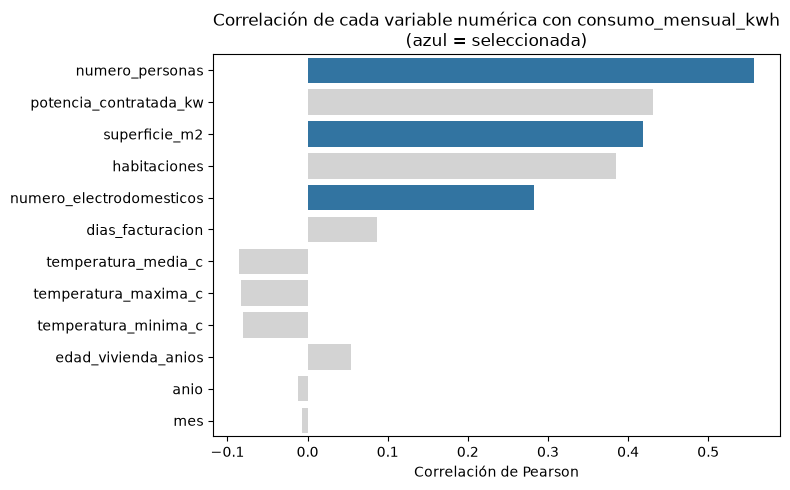

,correlacion
numero_personas,0.557
potencia_contratada_kw,0.431
superficie_m2,0.418
habitaciones,0.384
numero_electrodomesticos,0.283
dias_facturacion,0.087
temperatura_media_c,-0.086
temperatura_maxima_c,-0.082
temperatura_minima_c,-0.080
edad_vivienda_anios,0.054


In [14]:
corr = df_clean.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=corr.values, y=corr.index, hue=corr.index.isin(SET_AMPLIO), dodge=False,
            palette={True: "tab:blue", False: "lightgray"}, legend=False)
plt.title("Correlación de cada variable numérica con consumo_mensual_kwh\n(azul = seleccionada)")
plt.xlabel("Correlación de Pearson")
plt.ylabel("")
plt.tight_layout()
plt.show()
corr.round(3).to_frame("correlacion")

**Categóricas:** consumo medio por categoría. Cuanto mayor es la diferencia entre categorías, más información aporta la variable.

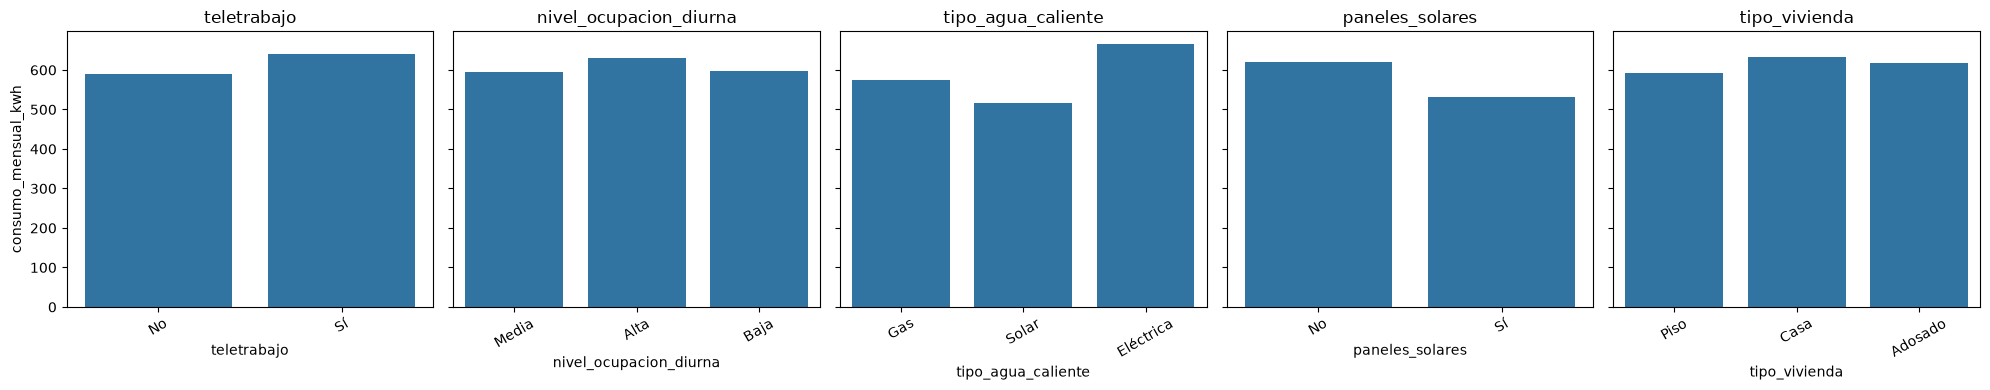

,diferencia_medias_kwh
tipo_agua_caliente,148.7
paneles_solares,89.0
teletrabajo,49.7
tipo_vivienda,41.0
nivel_ocupacion_diurna,35.0
tipo_calefaccion,16.8
zona_climatica,7.4
tipo_tarifa,6.2
nivel_aislamiento,5.4
aire_acondicionado,1.1


In [15]:
cat_sel = [c for c in SET_AMPLIO if c in cat_cols]
fig, axes = plt.subplots(1, len(cat_sel), figsize=(4 * len(cat_sel), 4), sharey=True)
for ax, c in zip(axes, cat_sel):
    sns.barplot(data=df_clean, x=c, y=TARGET, ax=ax, errorbar=None)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

rango = {c: df_clean.groupby(c)[TARGET].mean().pipe(lambda s: s.max() - s.min()) for c in cat_cols}
pd.Series(rango).sort_values(ascending=False).round(1).to_frame("diferencia_medias_kwh")

**Redundancia:** correlación entre variables candidatas que miden cosas parecidas.

In [16]:
df_clean[["superficie_m2", "habitaciones", "numero_personas", "potencia_contratada_kw"]].corr().round(2)

,superficie_m2,habitaciones,numero_personas,potencia_contratada_kw
superficie_m2,1.00,0.85,-0.00,-0.01
habitaciones,0.85,1.00,-0.00,-0.00
numero_personas,-0.00,-0.00,1.00,0.78
potencia_contratada_kw,-0.01,-0.00,0.78,1.00


## Parte 4 — Preparación de los datos para los modelos
### 4.1 División entrenamiento / test (70 % / 30 %)
Si evaluáramos el modelo con los mismos datos con los que aprende, un modelo que los memorizase obtendría un error casi nulo sin saber generalizar (**sobreajuste u *overfitting***). El conjunto de test simula viviendas nuevas que el modelo nunca ha visto, así que su error mide la capacidad real de predicción.

Se usa `random_state=42` para que la división sea reproducible: cualquiera que ejecute el notebook obtendrá exactamente los mismos conjuntos y resultados.

In [17]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=TARGET)
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print(f"Entrenamiento: {X_train.shape[0]} filas ({X_train.shape[0] / len(X):.0%})")
print(f"Test         : {X_test.shape[0]} filas ({X_test.shape[0] / len(X):.0%})")

Entrenamiento: 20957 filas (70%)
Test         : 8982 filas (30%)


### 4.2 Codificación y escalado
Los modelos solo trabajan con números, pero **codificar categorías como 0, 1, 2 inventa un orden y unas distancias que no existen** (p. ej. Piso=0, Casa=1, Adosado=2 haría creer al modelo que un adosado es "el doble" que una casa).

| Tipo de variable | Variables | Transformación |
|---|---|---|
| Numéricas | `numero_personas`, `superficie_m2`, `numero_electrodomesticos` | `StandardScaler` (media 0, desviación 1) |
| Binarias | `teletrabajo`, `paneles_solares` | 0 / 1 |
| Categóricas nominales | `tipo_vivienda`, `tipo_agua_caliente` | One-Hot (una columna 0/1 por categoría) |
| Categórica ordinal | `nivel_ocupacion_diurna` | One-Hot: aunque tiene orden, el efecto no es lineal (Baja ≈ Media, solo Alta sube el consumo), y codificarla 0/1/2 impondría saltos iguales |

**Escalado:** KNN mide distancias y la regresión lineal compara coeficientes; si una variable va de 30 a 283 (m²) y otra de 1 a 8 (personas), la de mayor rango dominaría. Los modelos de árboles no lo necesitan, pero no les perjudica.

**Evitar *data leakage*:** el preprocesado se ajusta **solo con el conjunto de entrenamiento** (dentro de un `Pipeline`), de modo que la media y desviación del escalado no contienen información del test.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

BINARIAS = ["teletrabajo", "paneles_solares"]

def make_preprocessor(features):
    """Build the encoding/scaling step for a given list of predictor variables."""
    numericas = [c for c in features if c in num_cols]
    binarias = [c for c in features if c in BINARIAS]
    nominales = [c for c in features if c in cat_cols and c not in BINARIAS]
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("bin", OneHotEncoder(drop="if_binary"), binarias),
        ("cat", OneHotEncoder(handle_unknown="ignore"), nominales),
    ])

for nombre, features in [("Reducido", SET_REDUCIDO), ("Amplio", SET_AMPLIO)]:
    prep = make_preprocessor(features).fit(X_train[features])
    cols = prep.get_feature_names_out()
    print(f"{nombre}: {len(features)} variables -> {len(cols)} columnas tras codificar")
    print("   ", list(cols))

Reducido: 5 variables -> 7 columnas tras codificar
    ['num__numero_personas', 'num__superficie_m2', 'num__numero_electrodomesticos', 'bin__teletrabajo_Sí', 'cat__nivel_ocupacion_diurna_Alta', 'cat__nivel_ocupacion_diurna_Baja', 'cat__nivel_ocupacion_diurna_Media']
Amplio: 8 variables -> 14 columnas tras codificar
    ['num__numero_personas', 'num__superficie_m2', 'num__numero_electrodomesticos', 'bin__teletrabajo_Sí', 'bin__paneles_solares_Sí', 'cat__nivel_ocupacion_diurna_Alta', 'cat__nivel_ocupacion_diurna_Baja', 'cat__nivel_ocupacion_diurna_Media', 'cat__tipo_agua_caliente_Eléctrica', 'cat__tipo_agua_caliente_Gas', 'cat__tipo_agua_caliente_Solar', 'cat__tipo_vivienda_Adosado', 'cat__tipo_vivienda_Casa', 'cat__tipo_vivienda_Piso']


## Parte 5 — Entrenamiento de los modelos
Se eligen 4 algoritmos de **familias distintas**, para que la comparación permita explicar *por qué* uno funciona mejor que otro:

| Modelo | Familia | Cómo aprende | Motivo de la elección |
|---|---|---|---|
| `LinearRegression` | Lineal | Ajusta `consumo = b0 + b1·x1 + … + bn·xn` minimizando el error cuadrático | Modelo de referencia (*baseline*): simple, rápido e interpretable. Solo capta relaciones lineales. |
| `RandomForestRegressor` | Ensamble de árboles (*bagging*) | Entrena muchos árboles en paralelo sobre muestras aleatorias y promedia sus predicciones | Capta relaciones no lineales e interacciones; robusto frente al sobreajuste. |
| `GradientBoostingRegressor` | Ensamble de árboles (*boosting*) | Entrena árboles en secuencia; cada uno corrige el error de los anteriores | Suele ser de los mejores en datos tabulares. |
| `MLPRegressor` | Red neuronal | Capas de neuronas que combinan las variables con funciones no lineales | Puede aprender relaciones complejas; requiere datos escalados y ajuste de hiperparámetros. |

**Hipótesis previa del alumno:** la regresión lineal obtendrá el menor MAE.

Cada modelo se entrena dentro de un `Pipeline` (preprocesado + modelo) para que el preprocesado se ajuste solo con el conjunto de entrenamiento.

In [19]:
import time
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

def make_models():
    return {
        "Regresión lineal": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=42),
        "Red neuronal (MLP)": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000,
                                           early_stopping=True, random_state=42),
    }

CONJUNTOS = {"Reducido (5)": SET_REDUCIDO, "Amplio (8)": SET_AMPLIO}
resultados, pipelines = [], {}

for nombre_set, features in CONJUNTOS.items():
    for nombre_modelo, modelo in make_models().items():
        pipe = Pipeline([("prep", make_preprocessor(features)), ("model", modelo)])
        t0 = time.perf_counter()
        pipe.fit(X_train[features], y_train)
        segundos = time.perf_counter() - t0
        mae_train = mean_absolute_error(y_train, pipe.predict(X_train[features]))
        mae_test = mean_absolute_error(y_test, pipe.predict(X_test[features]))
        pipelines[(nombre_set, nombre_modelo)] = pipe
        resultados.append({"Conjunto": nombre_set, "Modelo": nombre_modelo,
                           "MAE train": mae_train, "MAE test": mae_test,
                           "Tiempo (s)": segundos})
        print(f"{nombre_set:13} | {nombre_modelo:20} | MAE test = {mae_test:7.2f} kWh")

Reducido (5)  | Regresión lineal     | MAE test =   73.75 kWh


Reducido (5)  | Random Forest        | MAE test =   81.52 kWh


Reducido (5)  | Gradient Boosting    | MAE test =   74.16 kWh


Reducido (5)  | Red neuronal (MLP)   | MAE test =   73.80 kWh
Amplio (8)    | Regresión lineal     | MAE test =   52.57 kWh


Amplio (8)    | Random Forest        | MAE test =   54.69 kWh


Amplio (8)    | Gradient Boosting    | MAE test =   50.08 kWh


Amplio (8)    | Red neuronal (MLP)   | MAE test =   49.08 kWh


## Parte 6 — Evaluación (MAE)
El **MAE** es el error medio absoluto en kWh: un MAE de 80 significa que, de media, la predicción se desvía 80 kWh del consumo real. Cuanto menor, mejor.

Se muestra también el MAE en entrenamiento: si es mucho menor que el de test, el modelo ha memorizado los datos (**sobreajuste**).

In [20]:
res = pd.DataFrame(resultados)
res["Brecha train-test"] = res["MAE test"] - res["MAE train"]
res.sort_values("MAE test").round(2).reset_index(drop=True)

,Conjunto,Modelo,MAE train,MAE test,Tiempo (s),Brecha train-test
0,Amplio (8),Red neuronal (MLP),48.96,49.08,1.28,0.12
1,Amplio (8),Gradient Boosting,48.94,50.08,0.79,1.14
2,Amplio (8),Regresión lineal,52.44,52.57,0.01,0.13
3,Amplio (8),Random Forest,20.38,54.69,0.68,34.31
4,Reducido (5),Regresión lineal,73.65,73.75,0.01,0.10
5,Reducido (5),Red neuronal (MLP),73.67,73.80,0.71,0.13
6,Reducido (5),Gradient Boosting,72.81,74.16,0.60,1.36
7,Reducido (5),Random Forest,32.11,81.52,0.54,49.41


In [21]:
tabla = res.pivot(index="Modelo", columns="Conjunto", values="MAE test")[list(CONJUNTOS)]
tabla["Mejora al ampliar (kWh)"] = tabla["Reducido (5)"] - tabla["Amplio (8)"]
tabla["Mejora (%)"] = tabla["Mejora al ampliar (kWh)"] / tabla["Reducido (5)"] * 100
print("Referencia: MAE de predecir siempre la media =",
      round(mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())), 2), "kWh")
tabla.sort_values("Amplio (8)").round(2)

Referencia: MAE de predecir siempre la media = 115.62 kWh


Conjunto,Reducido (5),Amplio (8),Mejora al ampliar (kWh),Mejora (%)
Modelo,,,,
Red neuronal (MLP),73.80,49.08,24.73,33.50
Gradient Boosting,74.16,50.08,24.09,32.48
Regresión lineal,73.75,52.57,21.18,28.72
Random Forest,81.52,54.69,26.83,32.91


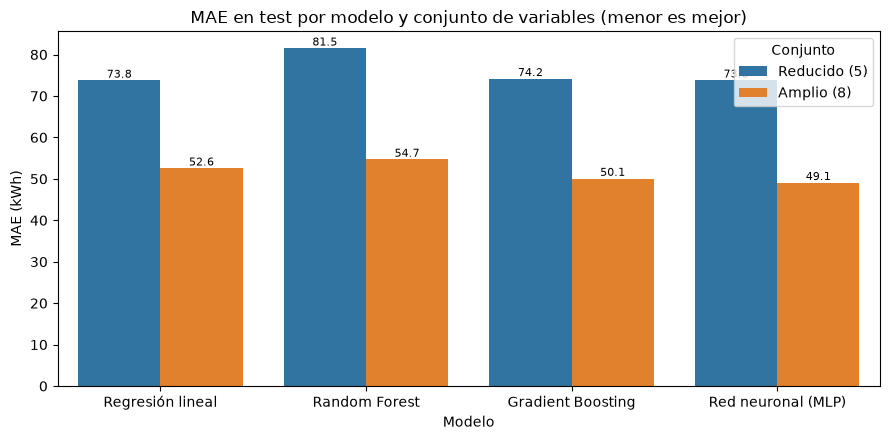

In [22]:
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=res, x="Modelo", y="MAE test", hue="Conjunto")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=8)
plt.title("MAE en test por modelo y conjunto de variables (menor es mejor)")
plt.ylabel("MAE (kWh)")
plt.tight_layout()
plt.show()

## Parte 7 — Corrección del sobreajuste de Random Forest
Con los valores por defecto (`max_depth=None`, `min_samples_leaf=1`) cada árbol crece hasta que cada hoja contiene una sola vivienda: memoriza el consumo exacto de cada registro, incluido el ruido aleatorio. Por eso su MAE de entrenamiento es muy inferior al de test.

**Solución:** limitar la complejidad de los árboles.
- `min_samples_leaf`: número mínimo de viviendas en cada hoja; la predicción pasa a ser un promedio de varias viviendas parecidas en lugar de copiar una sola.
- `max_depth`: número máximo de preguntas encadenadas en cada árbol.

Reducir los datos de entrenamiento **no** corrige el sobreajuste: con menos ejemplos es todavía más fácil memorizarlos.

Los hiperparámetros se eligen con **validación cruzada (5 particiones) sobre el conjunto de entrenamiento**: el test no se usa para decidir, solo para la evaluación final.

In [23]:
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([("prep", make_preprocessor(SET_AMPLIO)),
                    ("model", RandomForestRegressor(n_estimators=200, random_state=42))])
grid = GridSearchCV(
    rf_pipe,
    param_grid={"model__min_samples_leaf": [1, 5, 20, 50, 100],
                "model__max_depth": [None, 8, 12]},
    scoring="neg_mean_absolute_error", cv=5, n_jobs=-1, return_train_score=True,
)
grid.fit(X_train[SET_AMPLIO], y_train)

cv = pd.DataFrame(grid.cv_results_)
cv_tabla = pd.DataFrame({
    "max_depth": cv["param_model__max_depth"].map(lambda v: "Sin límite" if pd.isna(v) else int(v)),
    "min_samples_leaf": cv["param_model__min_samples_leaf"],
    "MAE train (CV)": -cv["mean_train_score"],
    "MAE validación (CV)": -cv["mean_test_score"],
}).sort_values("MAE validación (CV)").round(2).reset_index(drop=True)
print("Mejor configuración:", grid.best_params_)
cv_tabla

Mejor configuración: {'model__max_depth': 12, 'model__min_samples_leaf': 5}


,max_depth,min_samples_leaf,MAE train (CV),MAE validación (CV)
0,12,5,42.88,52.99
1,12,1,37.06,53.05
2,Sin límite,5,40.73,53.07
3,Sin límite,1,20.35,54.79
4,Sin límite,20,50.63,54.97
5,12,20,50.68,54.99
6,8,1,53.30,57.15
7,8,5,53.47,57.16
8,8,20,54.78,57.74
9,12,50,56.25,58.63


In [24]:
rf_best = grid.best_estimator_
mae_train_best = mean_absolute_error(y_train, rf_best.predict(X_train[SET_AMPLIO]))
mae_test_best = mean_absolute_error(y_test, rf_best.predict(X_test[SET_AMPLIO]))
base = res[(res["Conjunto"] == "Amplio (8)") & (res["Modelo"] == "Random Forest")].iloc[0]

pd.DataFrame({
    "MAE train": [base["MAE train"], mae_train_best],
    "MAE test": [base["MAE test"], mae_test_best],
}, index=["Random Forest por defecto", f"Random Forest ajustado {grid.best_params_}"]).assign(
    **{"Brecha train-test": lambda t: t["MAE test"] - t["MAE train"]}).round(2)

,MAE train,MAE test,Brecha train-test
Random Forest por defecto,20.38,54.69,34.31
"Random Forest ajustado {'model__max_depth': 12, 'model__min_samples_leaf': 5}",43.24,52.60,9.36


## Parte 8 — ¿Son fiables las diferencias entre modelos?
Una sola división train/test puede favorecer a un modelo por azar. Para comprobar si las diferencias de ~1 kWh son reales, se repite la evaluación con **validación cruzada de 5 particiones** sobre el conjunto de entrenamiento y se observa la media y la variabilidad (desviación típica) del MAE.

In [25]:
from sklearn.model_selection import cross_val_score

modelos_cv = make_models()
modelos_cv["Random Forest"] = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                                    random_state=42)
filas = []
for nombre, modelo in modelos_cv.items():
    pipe = Pipeline([("prep", make_preprocessor(SET_AMPLIO)), ("model", modelo)])
    scores = -cross_val_score(pipe, X_train[SET_AMPLIO], y_train, cv=5,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
    filas.append({"Modelo": nombre, "MAE medio (CV)": scores.mean(), "Desv. típica": scores.std(),
                  "MAE por partición": np.round(scores, 1)})
pd.DataFrame(filas).sort_values("MAE medio (CV)").round(2).reset_index(drop=True)

,Modelo,MAE medio (CV),Desv. típica,MAE por partición
0,Red neuronal (MLP),49.14,0.66,"[49.4, 49.5, 49.0, 47.9, 49.9]"
1,Gradient Boosting,50.09,0.58,"[50.2, 50.3, 50.2, 49.0, 50.7]"
2,Regresión lineal,52.47,0.76,"[52.7, 52.5, 52.9, 51.0, 53.2]"
3,Random Forest,52.99,0.50,"[53.1, 53.1, 53.3, 52.0, 53.5]"


### Importancia de las variables (Gradient Boosting, conjunto amplio)
Permite justificar qué variables usa realmente el modelo para predecir.

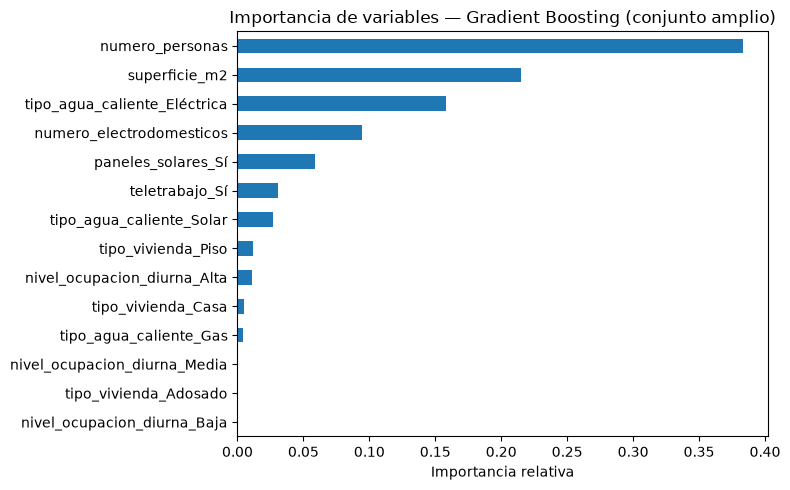

,importancia
numero_personas,0.383
superficie_m2,0.215
tipo_agua_caliente_Eléctrica,0.158
numero_electrodomesticos,0.095
paneles_solares_Sí,0.059
teletrabajo_Sí,0.031
tipo_agua_caliente_Solar,0.027
tipo_vivienda_Piso,0.012
nivel_ocupacion_diurna_Alta,0.011
tipo_vivienda_Casa,0.005


In [26]:
gb = pipelines[("Amplio (8)", "Gradient Boosting")]
imp = pd.Series(gb.named_steps["model"].feature_importances_,
                index=gb.named_steps["prep"].get_feature_names_out()).sort_values()
imp.index = imp.index.str.replace(r"^(num|bin|cat)__", "", regex=True)
plt.figure(figsize=(8, 5))
imp.plot.barh()
plt.title("Importancia de variables — Gradient Boosting (conjunto amplio)")
plt.xlabel("Importancia relativa")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(3).to_frame("importancia")